In [93]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import os, glob

In [94]:
import matplotlib as mpl
import matplotlib.font_manager as fm
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple
from matplotlib.ticker import MultipleLocator

FONT_DIR = os.path.expanduser("~/fonts/SourceSans3")

for f in glob.glob(os.path.join(FONT_DIR, "*.ttf")):
    fm.fontManager.addfont(f)

available = {f.name for f in fm.fontManager.ttflist}
FAMILY = next((n for n in ("Source Sans 3", "Source Sans Pro") if n in available), None)
if FAMILY is None:
    raise RuntimeError(f"Source Sans not found. Check FONT_DIR: {FONT_DIR}")

W = 418.25372 / 72.27   # \textwidth in inches (~5.787)
W_HALF = 0.48 * W       # two panels side by side

mpl.rcParams.update({
    # --- Text / fonts ---
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": [FAMILY],
    "mathtext.fontset": "custom",
    "mathtext.rm": FAMILY,
    "mathtext.it": f"{FAMILY}:italic",
    "mathtext.bf": f"{FAMILY}:bold",
    "mathtext.sf": FAMILY,
    "mathtext.default": "it",
    "mathtext.fallback": "cm",     
    "axes.unicode_minus": True,    

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 10,

    "axes.linewidth": 0.8,
    "lines.linewidth": 1.3,
    "lines.markersize": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "xtick.minor.size": 2,
    "ytick.minor.size": 2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.4,

    "legend.frameon": False,
    "legend.handlelength": 1.5,

    "figure.figsize": (W, W),
    "figure.constrained_layout.use": True,
    "savefig.dpi": 300,             
    "savefig.format": "pdf",
    "pdf.fonttype": 42,    
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [95]:
years = np.arange(1991, 2006, 1)
path = '/jetfs/scratch/psplechtna/thesisdata/oper/'

In [96]:
tsr = xr.open_mfdataset([path+f'1991-2020/{year}_tsr.nc' for year in years])

In [97]:
yrs_tsr_mean = tsr.groupby('release_date.year').mean(dim='release_date').load()
yrs_tsr_std= tsr.groupby('release_date.year').std(dim='release_date').load()

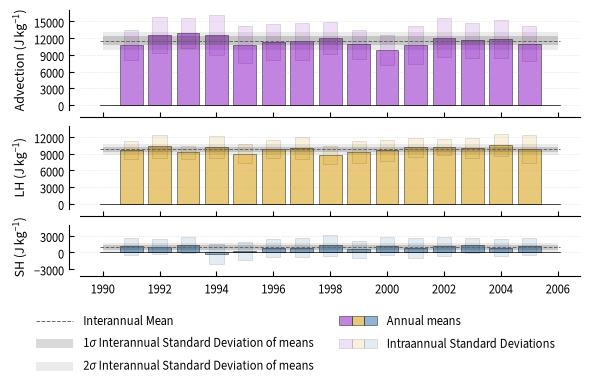

In [175]:
ylims = [(-1000, 17000), (-1000, 14000), (-3000, 5000)]
ratios = [hi - lo for lo, hi in ylims]
tick_step = 3000

fig, ax = plt.subplots(
    3, 1, figsize=(W,0.65*W), sharex=True,
    gridspec_kw={'height_ratios': ratios}
)

x_lowhigh = np.arange(yrs_tsr_mean.year[0]-1, yrs_tsr_mean.year[-1]+2, 1)
xes = yrs_tsr_mean.year

ax[0].bar(xes, yrs_tsr_mean.advection, color='darkorchid', alpha=0.6, edgecolor='k', linewidth=0.5, label='Annual means')
ax[0].bar(xes, 2*yrs_tsr_std.advection, bottom=yrs_tsr_mean.advection-yrs_tsr_std.advection, 
          color='darkorchid', width=0.5, alpha=0.15, edgecolor='k', linewidth=0.5, label='Intraannual Standard Deviations')
ax[0].axhline(yrs_tsr_mean.mean(dim='year').advection, xmin=0.04, xmax=0.96, color='0.4', linewidth=0.7, linestyle='--', label='Interannual Mean')
ax[0].fill_between(x_lowhigh, yrs_tsr_mean.mean(dim='year').advection - yrs_tsr_mean.std(dim='year').advection, 
                   yrs_tsr_mean.mean(dim='year').advection + yrs_tsr_mean.std(dim='year').advection, facecolor='k', alpha=0.15,
                   label=r'1$\sigma$ Interannual Standard Deviation of means')
ax[0].fill_between(x_lowhigh, yrs_tsr_mean.mean(dim='year').advection - 2*yrs_tsr_mean.std(dim='year').advection, 
                   yrs_tsr_mean.mean(dim='year').advection + 2*yrs_tsr_mean.std(dim='year').advection, facecolor='k', alpha=0.08,
                   label=r'2$\sigma$ Interannual Standard Deviation of means')
ax[0].set_ylabel(r'Advection ($\mathrm{J\,kg^{-1}}$)')

ax[1].bar(xes, yrs_tsr_mean.flux_lh, color='goldenrod', alpha=0.6, edgecolor='k', linewidth=0.5)
ax[1].bar(xes, 2*yrs_tsr_std.flux_lh, bottom=yrs_tsr_mean.flux_lh-yrs_tsr_std.flux_lh, 
          color='goldenrod', width=0.5, alpha=0.15, edgecolor='k', linewidth=0.5)
ax[1].axhline(yrs_tsr_mean.mean(dim='year').flux_lh, xmin=0.04, xmax=0.96, color='0.4', linewidth=0.7, linestyle='--')
ax[1].fill_between(x_lowhigh, yrs_tsr_mean.mean(dim='year').flux_lh - yrs_tsr_mean.std(dim='year').flux_lh, 
                   yrs_tsr_mean.mean(dim='year').flux_lh + yrs_tsr_mean.std(dim='year').flux_lh, facecolor='k', alpha=0.15)
ax[1].fill_between(x_lowhigh, yrs_tsr_mean.mean(dim='year').flux_lh - 2*yrs_tsr_mean.std(dim='year').flux_lh, 
                   yrs_tsr_mean.mean(dim='year').flux_lh + 2*yrs_tsr_mean.std(dim='year').flux_lh, facecolor='k', alpha=0.08)
ax[1].set_ylabel(r'LH ($\mathrm{J\,kg^{-1}}$)')

ax[2].bar(xes, yrs_tsr_mean.flux_sh, color='steelblue', alpha=0.6, edgecolor='k', linewidth=0.5)
ax[2].bar(xes, 2*yrs_tsr_std.flux_sh, bottom=yrs_tsr_mean.flux_sh-yrs_tsr_std.flux_sh, 
          color='steelblue', width=0.5, alpha=0.15, edgecolor='k', linewidth=0.5)
ax[2].axhline(yrs_tsr_mean.mean(dim='year').flux_sh, xmin=0.04, xmax=0.96, color='0.4', linewidth=0.7, linestyle='--')
ax[2].fill_between(x_lowhigh, yrs_tsr_mean.mean(dim='year').flux_sh - yrs_tsr_mean.std(dim='year').flux_sh, 
                   yrs_tsr_mean.mean(dim='year').flux_sh + yrs_tsr_mean.std(dim='year').flux_sh, facecolor='k', alpha=0.15)
ax[2].fill_between(x_lowhigh, yrs_tsr_mean.mean(dim='year').flux_sh - 2*yrs_tsr_mean.std(dim='year').flux_sh, 
                   yrs_tsr_mean.mean(dim='year').flux_sh + 2*yrs_tsr_mean.std(dim='year').flux_sh, facecolor='k', alpha=0.08)
ax[2].set_ylabel(r'SH ($\mathrm{J\,kg^{-1}}$)')


for a, (lo, hi) in zip(ax, ylims):
    a.axhline(0, color='k', xmin=0.04, xmax=0.96, linewidth=0.5)
    a.grid(ls=':', alpha=0.5, axis='y')
    #a.set_ylabel(r'MSE ($\mathrm{J\,kg^{-1}}$)')
    for spine in ['top', 'right']:
        a.spines[spine].set_visible(False)
    a.spines.left.set_position(('outward', 8))
    a.spines.bottom.set_position(('outward', 5))
    a.set_ylim(lo, hi)
    a.yaxis.set_major_locator(MultipleLocator(tick_step))

colors = ['darkorchid', 'goldenrod', 'steelblue']
# proxy patches that mimic the bars
mean_handles = tuple(Patch(facecolor=c, alpha=0.6, edgecolor='k', linewidth=0.5) for c in colors)
std_handles  = tuple(Patch(facecolor=c, alpha=0.15, edgecolor='k', linewidth=0.5) for c in colors)

handles, labels = ax[0].get_legend_handles_labels()
handles[labels.index('Annual means')] = mean_handles
handles[labels.index('Intraannual Standard Deviations')] = std_handles

fig.legend(
    handles, labels,
    loc='outside lower center', ncol=2,
    handlelength=3,   # a bit wider to fit three boxes
    handler_map={tuple: HandlerTuple(ndivide=None, pad=0)},
)
#fig.savefig('/jetfs/home/psplechtna/plots/yearly_terms.pdf')

In [ ]:
yr = tsr["release_date"].dt.year                      # DataArray over release_date
mean_per_release = yrs_tsr_mean.sel(year=yr)          # (release_date), aligned release by release
tsr_within = tsr - mean_per_release                   # within view for all variables

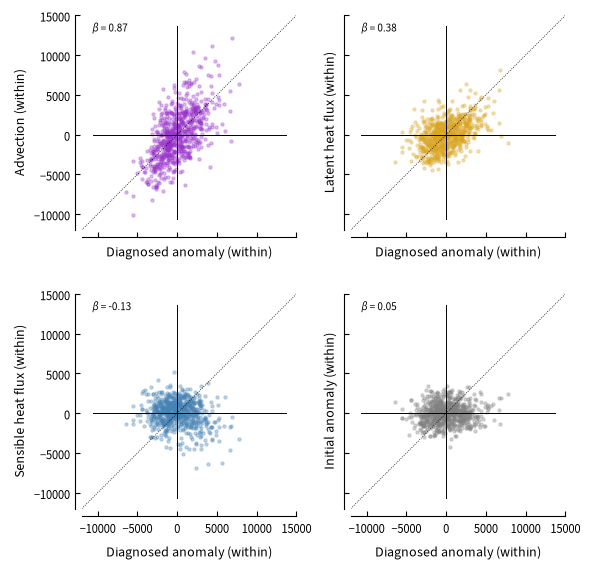

In [128]:
mode = "within"          # "within" | "pooled"

terms_plot = {
    "advection":     ("Advection",          "darkorchid"),
    "flux_lh":       ("Latent heat flux",   "goldenrod"),
    "flux_sh":       ("Sensible heat flux", "steelblue"),
    "init_anomaly":  ("Initial anomaly",    "grey"),
}

def prep(var):
    if mode == "within":
        return (tsr[var] - mean_per_release[var])
    return tsr[var]

xD = np.asarray(prep("diag_anomaly"), dtype=float)

fig, ax = plt.subplots(2, 2, figsize=(W, W), sharex=True, sharey=True,
                       constrained_layout=True)

lim = (-12000, 15000)
ticks = np.arange(-10000, 15001, 5000)

for a, (var, (ylab, col)) in zip(ax.flatten(), terms_plot.items()):
    y = np.asarray(prep(var), dtype=float)
    a.scatter(xD, y, color=col, alpha=0.3, s=5)

    # least-squares slope of the term on D = beta in the chosen mode
    ok = np.isfinite(xD) & np.isfinite(y)
    beta_ = np.cov(xD[ok], y[ok])[0, 1] / np.var(xD[ok], ddof=1)
    a.text(0.05, 0.92, rf"$\beta$ = {beta_:.2f}", transform=a.transAxes, fontsize=8)

    a.set_xlim(lim); a.set_ylim(lim)
    a.set_xticks(ticks); a.set_yticks(ticks)
    a.set_aspect("equal", adjustable="box")
    a.set_xlabel(f"Diagnosed anomaly ({mode})")
    a.set_ylabel(f"{ylab} ({mode})")
    a.spines.bottom.set_position(("outward", 5))
    a.spines.left.set_position(("outward", 5))
    a.axhline(0, xmin=0.05, xmax=0.95, color="k", linewidth=0.7)
    a.axvline(0, ymin=0.05, ymax=0.95, color="k", linewidth=0.7)
    a.plot(lim, lim, color="k", ls=":", lw=0.6)   # 1:1 line (beta = 1)